### KNN

K-nearest neighbors of a record x are data points that have the k smallest distance to x

usually k is choesen by usign the formula --> k = sqrt(N) where N is the number of samples in the training set 

lazy learner (the classification is often slow)

**Evaluation Strategy all models are evaluated using stratified cross-validation.**
**Model selection is based on macro F1-score to account for class imbalance.**

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import math as m 

In [2]:
import scipy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("../data/processed/board_games_clean.csv")

df.head()

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime,belong_to_family
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,1,0.000000,0
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,2,9.349442,0
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,3,37.468764,0
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,1,0.000000,0
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,2,9.349442,0


In [4]:

# creo la colonna player range:
df['PlayerRange'] = df['MaxPlayers'] - df['MinPlayers']
current_year = 2026
df["CurrentYear"] = current_year - df["YearPublished"]
df["WeightPerAge"] = df["ComWeight"] / (df["ComAgeRec"] +1)


In [5]:
features = ["CurrentYear","ComWeight","belong_to_family","NumOwned","NumWish"]
#categorie = [col for col in df.columns if col.startswith('Cat:')]
X = df[features].values
y = df['Rating'].values



In [6]:
# partitioning 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state= 1
)
print(np.unique(y, return_counts=True)[1] / len(y))
print(np.unique(y_train, return_counts=True)[1] / len(y_train))
print(np.unique(y_test, return_counts=True)[1] / len(y_test))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)





[0.32219708 0.44658932 0.23121359]
[0.32215357 0.44660194 0.23124448]
[0.32226233 0.4465704  0.23116727]


In [7]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors= 100, metric= "manhattan", weights= "uniform")
clf.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",100
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'


In [8]:

y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

In [9]:
print('Train Accuracy %s' % accuracy_score(y_train, y_train_pred))
print('Train F1-score %s' % f1_score(y_train, y_train_pred, average=None))
print()

print('Test Accuracy %s' % accuracy_score(y_test, y_test_pred))
print('Test F1-score %s' % f1_score(y_test, y_test_pred, average=None))

Train Accuracy 0.689801813367568
Train F1-score [0.72207328 0.68685866 0.64643641]

Test Accuracy 0.6824308062575211
Test F1-score [0.70956522 0.68068266 0.64483477]


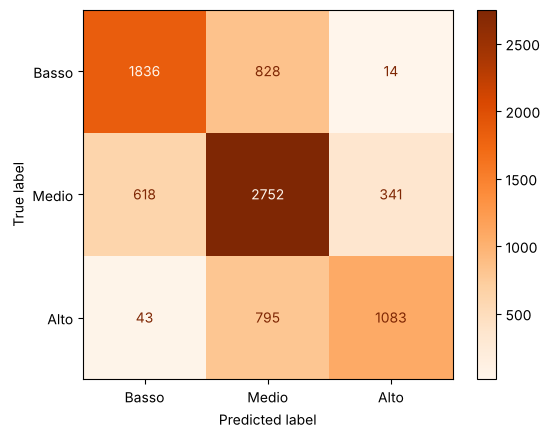

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Basso', 'Medio', 'Alto'])
disp.plot(cmap='Oranges')
plt.show()

In [11]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           1       0.74      0.69      0.71      2678
           2       0.63      0.74      0.68      3711
           3       0.75      0.56      0.64      1921

    accuracy                           0.68      8310
   macro avg       0.71      0.66      0.68      8310
weighted avg       0.69      0.68      0.68      8310



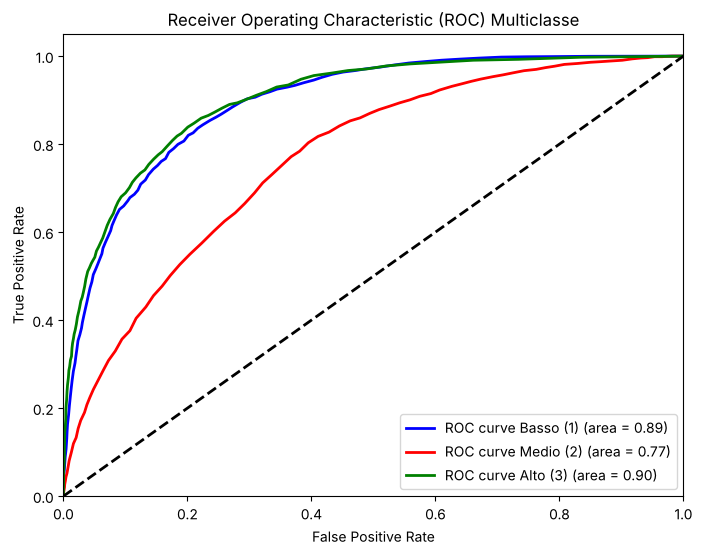

In [12]:
# ROC curve (one vs. rest)
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc


y_score = clf.predict_proba(X_test)

# 1. Binarizziamo y_test per le 3 classi
y_test_bin = label_binarize(y_test, classes=[1, 2, 3])
n_classes = y_test_bin.shape[1]

# 2. Calcoliamo ROC e AUC per ogni classe
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 3. Plot delle curve
plt.figure(figsize=(8, 6))
colors = ['blue', 'red', 'green']
labels = ['Basso (1)', 'Medio (2)', 'Alto (3)']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve {labels[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2) # Linea diagonale del caso
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Multiclasse')
plt.legend(loc="lower right")
plt.show()


da questa Roc curve possiamo vedere come il modello è molto bravo a classificare correttamente i giochi con rating "alto" ed i giochi con rating "basso" il rating "medio" è quello che da più problemi (è più probabile che il rating "medio" venga confuso con altre categorie come già mostrato dalla confusion matrix) perchè succede questo: 

1) il rating medio è quello con pià giochi quindi il modello lo usa come "rifugio" quando è incerto sul da farsi 
2) il rating medio è sicuramente quello con i confini più sfumati 

In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [80,90,100,110, 120]
}

# 2. Creiamo il modello base
dt_base = KNeighborsClassifier()

# 3. Configuriamo la ricerca automatica
# cv=5 significa che proverà ogni combinazione su 5 "fette" diverse di dati
grid_search = GridSearchCV(estimator=dt_base, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='accuracy', 
                           verbose=1)

# 4. Lanciamo la ricerca sui dati di training
grid_search.fit(X_train, y_train)

# 5. Risultati
print(f"Migliori parametri trovati: {grid_search.best_params_}")
print(f"Migliore accuracy media in Cross-Validation: {grid_search.best_score_:.4f}")

# Ora puoi usare il modello "ottimizzato" per vedere la Test Accuracy finale
best_model = grid_search.best_estimator_
test_acc = best_model.score(X_test, y_test)
print(f"Accuracy finale sul Test Set: {test_acc:.4f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits


Migliori parametri trovati: {'n_neighbors': 100}
Migliore accuracy media in Cross-Validation: 0.6782


Accuracy finale sul Test Set: 0.6816


### NAIVE BAYES 

Assumiamo che tutte le variabili siano indipendenti fra di loro 



In [14]:
from sklearn.naive_bayes import GaussianNB, CategoricalNB

In [15]:
clf_bayes = GaussianNB()

In [16]:
%%time
clf_bayes.fit(X_train, y_train)

CPU times: user 3.8 ms, sys: 0 ns, total: 3.8 ms
Wall time: 3.81 ms


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[4015.,5566.,2882.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.32,0.45,0.23]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[1,2,3]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 5)","[[ 0.46,-0.51,-0.16,-0.37,-0.72], [-0.07,-0.01,-0.03, 0.03, 0.1 ], [-0.5 , 0.73, 0.29, 0.45, 0.81]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 5)","[[1.16,0.58,0.83,0.53,0.4 ], [0.89,0.82,0.97,0.87,0.66], [0.45,1.03,1.17,1.5 ,1.1 ]]"


In [17]:
y_pred = clf_bayes.predict(X_test)
y_pred

array([1, 3, 2, ..., 3, 1, 2], shape=(8310,))

In [18]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.62      0.73      0.67      2678
           2       0.59      0.56      0.57      3711
           3       0.62      0.52      0.57      1921

    accuracy                           0.61      8310
   macro avg       0.61      0.60      0.60      8310
weighted avg       0.61      0.61      0.60      8310



In [19]:
clf_bayes.predict_proba(X_test)

array([[7.58318023e-01, 2.26705389e-01, 1.49765881e-02],
       [3.42258587e-03, 4.22083339e-01, 5.74494075e-01],
       [1.00310860e-01, 5.26414949e-01, 3.73274190e-01],
       ...,
       [2.09578312e-06, 7.59815172e-02, 9.24016387e-01],
       [6.44007884e-01, 3.32078121e-01, 2.39139946e-02],
       [1.33280598e-01, 7.68460850e-01, 9.82585514e-02]], shape=(8310, 3))

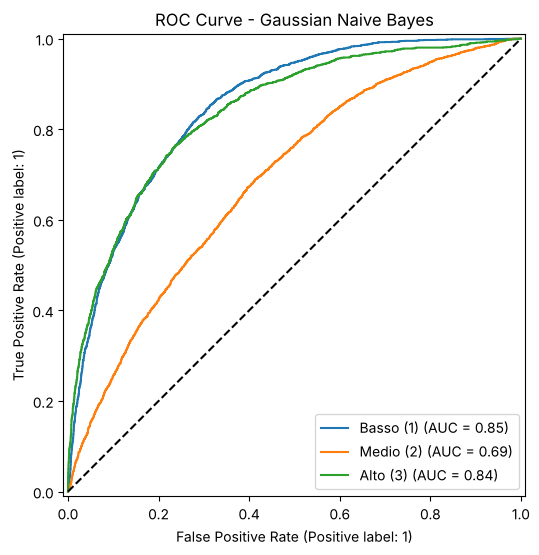

0.7917368933170862


In [20]:
# ROC curve (one vs. rest)
from sklearn.metrics import RocCurveDisplay
proba = clf_bayes.predict_proba(X_test)
fig, ax = plt.subplots(figsize=(8, 6))
for i, label in enumerate(['Basso (1)', 'Medio (2)', 'Alto (3)']):
    RocCurveDisplay.from_predictions((y_test == clf_bayes.classes_[i]).astype(int), proba[:, i], name=label, ax=ax)
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC Curve - Gaussian Naive Bayes')
plt.show()
print(roc_auc_score(y_test, clf_bayes.predict_proba(X_test), multi_class="ovr", average="macro"))

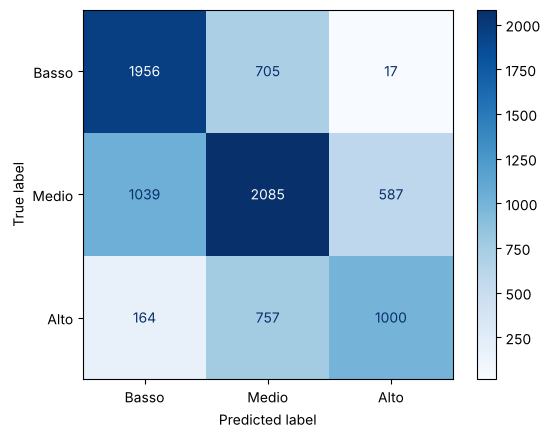

In [21]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Basso', 'Medio', 'Alto'])
disp.plot(cmap='Blues')
plt.show()

In [22]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    
    "var_smoothing":np.logspace(0, -9, num=10)
}

# 2. Creiamo il modello base
dt_base = GaussianNB()

# 3. Configuriamo la ricerca automatica
# cv=5 significa che proverà ogni combinazione su 5 "fette" diverse di dati
grid_search = GridSearchCV(estimator=dt_base, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='accuracy', 
                           verbose=1)

# 4. Lanciamo la ricerca sui dati di training
grid_search.fit(X_train, y_train)

# 5. Risultati
print(f"Migliori parametri trovati: {grid_search.best_params_}")
print(f"Migliore accuracy media in Cross-Validation: {grid_search.best_score_:.4f}")

# Ora puoi usare il modello "ottimizzato" per vedere la Test Accuracy finale
best_model = grid_search.best_estimator_
test_acc = best_model.score(X_test, y_test)
print(f"Accuracy finale sul Test Set: {test_acc:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits


Migliori parametri trovati: {'var_smoothing': np.float64(1.0)}
Migliore accuracy media in Cross-Validation: 0.6097
Accuracy finale sul Test Set: 0.6178


si nota un calo di performance rispetto al KNN, probabilmente perchè le nostre variabili sono correlate fra di loro mentre il Naive bayes assume che siano indipendenti 

il fatto che la cross validation ci dia come miglior parametro var_smoothing = 1.0 [ammortizzazione massima possibile dei dati] sta a significare che i nostri dati non hanno assolutamente una distribuzione gaussiana (ci sono molte distribuzioni long_tailed)


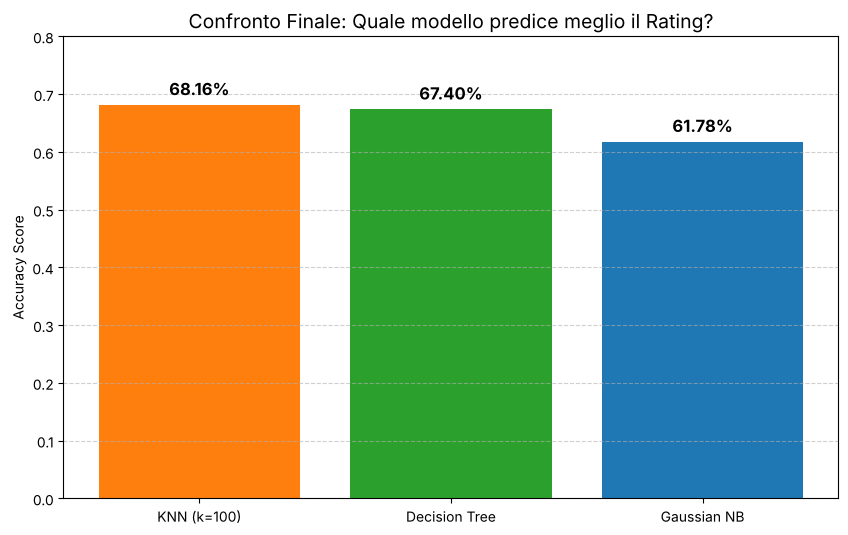

In [23]:
import matplotlib.pyplot as plt

# Risultati finali consolidati
modelli = ['KNN (k=100)', 'Decision Tree', 'Gaussian NB']
accuracy_scores = [0.6816, 0.6740, 0.6178]

plt.figure(figsize=(10, 6))
colors = ['#ff7f0e', '#2ca02c', '#1f77b4'] # Arancio per KNN, Verde per DT, Blu per NB
bars = plt.bar(modelli, accuracy_scores, color=colors)

# Aggiungiamo le percentuali sopra ogni barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, 
             f'{yval:.2%}', ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.ylim(0, 0.8)
plt.title('Confronto Finale: Quale modello predice meglio il Rating?', fontsize=14)
plt.ylabel('Accuracy Score')
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

Modello,Test Accuracy (Reale),CV Accuracy (Media),Commento
KNN (k=100),68.16%,67.82%,Vincitore. Il più preciso e molto stabile.
Decision Tree,67.40%,66.49%,"Ottimo secondo, molto vicino al KNN."
Gaussian NB,61.78%,60.97%,Il meno efficace per questi dati.

**lista di tutti gli evaluation method utilizzati** 

1) train test split (uso di training test e testing set) [per allenare i modelli e valutare performance su risutlati non visti]

2) stratified cross validation (suddivisione dei dati in parti uguali con stessa distribuzione)

3) GridSearchCV (ripeto la classificazione con diversi paramentri scelti da me per vedere quello che performa meglio ed uso F1 Macro come metrica di scoring)

4) accuracy (metrica di riferimento iniziale)

5) F1 score macro[media ] (metrica principale di evaluation) [usata in cross validation e sul test set {classifition_report}]

6) confusion matrix 

7) classification_report (precision, recall ed F1 score per classe )

8) Roc curve 
